# 🧠 Comment Category Prediction — ML Project (t12026)

In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/comment-category-prediction-challenge/Sample.csv
/kaggle/input/comment-category-prediction-challenge/train.csv
/kaggle/input/comment-category-prediction-challenge/test.csv


### Importing libraries

In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud, STOPWORDS
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, MinMaxScaler,StandardScaler, MaxAbsScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, FunctionTransformer
import re
from scipy import sparse
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.metrics import f1_score, classification_report, accuracy_score, confusion_matrix
from lightgbm import LGBMClassifier
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.svm import LinearSVC 
from sklearn.naive_bayes import ComplementNB, MultinomialNB

---
## Section 1 — Data Loading
Loading all the three files
- `train.csv` — labeled data used to train our model
- `test.csv` — unlabeled data we need to predict
- `Sample.csv` — shows the required submission format (ID, label)

In [3]:
data=pd.read_csv("/kaggle/input/comment-category-prediction-challenge/train.csv")
test=pd.read_csv("/kaggle/input/comment-category-prediction-challenge/test.csv")
sample=pd.read_csv("/kaggle/input/comment-category-prediction-challenge/Sample.csv")

### chacking the all the datset shape for the 

print("train data shape :", data.shape)
print("test data shape :" ,test.shape)
print("sample data shape :", sample.shape)

train data shape : (198000, 15)
test data shape : (102000, 14)
sample data shape : (102000, 2)


### EDA = Exploratory Data Analysis 📊

### Shape and Column Overview

In [4]:

print("=" * 60)
print("train train")
print("=" * 60)
print(f"Rows: {data.shape[0]:,}  |  Columns: {data.shape[1]}")
print("\ncolumns:", data.columns.tolist())

print("\n" + "=" * 60)
print("test datset")
print("=" * 60)
print(f"Rows: {test.shape[0]:,}  |  Columns: {test.shape[1]}")

print("\n\nFirst 3 rows of training data:")
display(data.head(3))

train train
Rows: 198,000  |  Columns: 15

columns: ['created_date', 'post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1', 'if_2', 'race', 'religion', 'gender', 'disability', 'comment', 'label']

test datset
Rows: 102,000  |  Columns: 14


First 3 rows of training data:


,created_date,post_id,emoticon_1,emoticon_2,emoticon_3,upvote,downvote,if_1,if_2,race,religion,gender,disability,comment,label
0,2024-01-18 08:43:57.397508+00:00,73,0,0,0,0,1,0,10,NaN,NaN,NaN,False,She might be a bright spot for a party keou on...,2
1,2024-03-24 21:43:11.490017+00:00,39,0,0,0,6,0,0,4,NaN,NaN,NaN,False,"Under Alaska law, a non-tribal member is not b...",0
2,2024-04-24 20:32:17.014931+00:00,31,0,1,1,0,0,0,10,NaN,NaN,NaN,False,in the future please spare me your strawman dr...,2


### Feature Type Identification

Understanding the data type of each column is critical for preprocessing

In [5]:
print(data.dtypes)

print("\n--- Grouped by type ---")
for dtype_name, dtype_group in data.dtypes.groupby(data.dtypes):
    print(f"\n[{dtype_name}] → {dtype_group.index.tolist()}")

created_date    object
post_id          int64
emoticon_1       int64
emoticon_2       int64
emoticon_3       int64
upvote           int64
downvote         int64
if_1             int64
if_2             int64
race            object
religion        object
gender          object
disability        bool
comment         object
label            int64
dtype: object

--- Grouped by type ---

[bool] → ['disability']

[int64] → ['post_id', 'emoticon_1', 'emoticon_2', 'emoticon_3', 'upvote', 'downvote', 'if_1', 'if_2', 'label']

[object] → ['created_date', 'race', 'religion', 'gender', 'comment']


**Key observations:**
- `created_date` is an **object** (string) but actually stores timestamps — we will parse it to extract hour and day-of-week signals.
- `disability` is a **boolean** — we will convert it to integer (0/1) for the model.
- `race`, `religion`, `gender` are **categorical objects** — but as we'll see in the next section, they are overwhelmingly missing and will be dropped.
- `comment` is a **text column** — the richest signal in the dataset. We will vectorise it using TF-IDF.
- `label` is the **target** (integer 0–3).

### Duplicate Detection

In [6]:
train_dups = data.duplicated().sum()
test_dups  = test.duplicated().sum()

print(f"Duplicates in train : {train_dups}")
print(f"Duplicates in test  : {test_dups}")

# Drop if any exist
if train_dups > 0:
    data = data.drop_duplicates()
    print(f"Dropped {train_dups} duplicate rows from train. New shape: {data.shape}")
else:
    print("No duplicates found — data is clean ✅")

Duplicates in train : 0
Duplicates in test  : 0
No duplicates found — data is clean ✅


### Missing Value Analysis


In [7]:
def missing_report(df, name="Dataset"):
    miss = pd.DataFrame({
        'Missing Count': df.isnull().sum(),
        'Missing %'    : (df.isnull().sum() / len(df) * 100).round(2)
    })
    miss = miss[miss['Missing Count'] > 0].sort_values('Missing %', ascending=False)
    print(f"\n=== {name} — Missing Values ===")
    print(miss if not miss.empty else "No missing values.")
    return miss

miss_train = missing_report(data,  "Train")
miss_test  = missing_report(test,  "Test")


=== Train — Missing Values ===
          Missing Count  Missing %
race             145423      73.45
religion         145423      73.45
gender           145423      73.45
comment               1       0.00

=== Test — Missing Values ===
          Missing Count  Missing %
race              75269      73.79
religion          75269      73.79
gender            75269      73.79


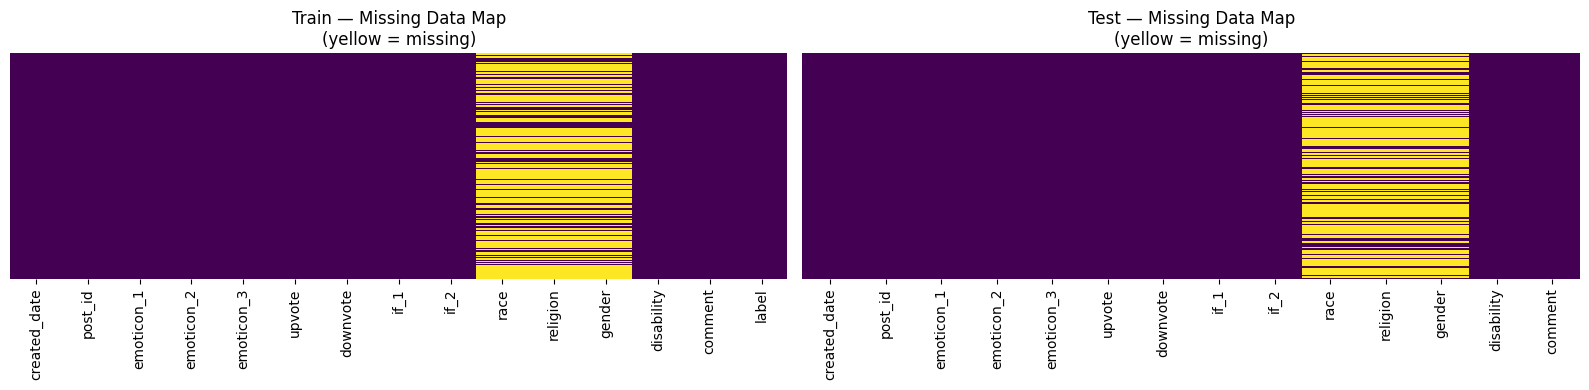


race/religion/gender missing in TRAIN : 73.4%
race/religion/gender missing in TEST  : 73.8%


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4))

sns.heatmap(data.isnull(), cbar=False, yticklabels=False,
            cmap='viridis', ax=axes[0])
axes[0].set_title("Train — Missing Data Map\n(yellow = missing)")

sns.heatmap(test.isnull(), cbar=False, yticklabels=False,
            cmap='viridis', ax=axes[1])
axes[1].set_title("Test — Missing Data Map\n(yellow = missing)")

plt.tight_layout()
plt.show()

# Precise percentages
print(f"\nrace/religion/gender missing in TRAIN : "
      f"{145423/len(data)*100:.1f}%")
print(f"race/religion/gender missing in TEST  : "
      f"{75269/len(test)*100:.1f}%")

**Decision — Drop `race`, `religion`, `gender`:**

The three columns `race`, `religion`, and `gender` are missing in **~73%** of both train and test rows.  
A common rule of thumb is to drop any column with >50–70% missing data because:
1. There is not enough information to reliably impute so many values — any imputation would be mostly guessed data, introducing artificial noise.
2. Keeping them and imputing could bias the model toward a fabricated signal.
3. The ~27% of non-missing rows don't provide enough coverage for these features to be useful.

**Decision — Fill `comment` NaN with empty string:**  
Only 1 row in train has a missing comment. We fill it with `""` so the TF-IDF vectoriser doesn't break.

### Statistical Summary and Outlier Assessment

In [9]:
print("=== Train — Numerical Summary ===")
display(data.describe().T.style.background_gradient(cmap='Blues'))

print("\n=== Test — Numerical Summary ===")
display(test.describe().T.style.background_gradient(cmap='Greens'))

=== Train — Numerical Summary ===


,count,mean,std,min,25%,50%,75%,max
post_id,198000.000000,68.447429,27.948390,20.000000,39.000000,72.000000,72.000000,129.000000
emoticon_1,198000.000000,0.279768,1.023234,0.000000,0.000000,0.000000,0.000000,47.000000
emoticon_2,198000.000000,0.048338,0.258477,0.000000,0.000000,0.000000,0.000000,11.000000
emoticon_3,198000.000000,0.121071,0.481013,0.000000,0.000000,0.000000,0.000000,17.000000
upvote,198000.000000,2.607975,5.054763,0.000000,0.000000,1.000000,3.000000,201.000000
downvote,198000.000000,0.666394,2.044335,0.000000,0.000000,0.000000,1.000000,107.000000
if_1,198000.000000,1.906152,25.635752,0.000000,0.000000,0.000000,4.000000,1860.000000
if_2,198000.000000,7.956212,14.839464,3.000000,4.000000,6.000000,10.000000,1833.000000
label,198000.000000,0.793965,0.979808,0.000000,0.000000,0.000000,2.000000,3.000000



=== Test — Numerical Summary ===


,count,mean,std,min,25%,50%,75%,max
post_id,102000.000000,68.359422,27.923491,24.000000,39.000000,72.000000,72.000000,129.000000
emoticon_1,102000.000000,0.280078,1.043353,0.000000,0.000000,0.000000,0.000000,95.000000
emoticon_2,102000.000000,0.048353,0.257278,0.000000,0.000000,0.000000,0.000000,8.000000
emoticon_3,102000.000000,0.118902,0.480484,0.000000,0.000000,0.000000,0.000000,19.000000
upvote,102000.000000,2.609402,4.966033,0.000000,0.000000,1.000000,3.000000,189.000000
downvote,102000.000000,0.661667,1.965536,0.000000,0.000000,0.000000,1.000000,95.000000
if_1,102000.000000,1.903078,26.273483,0.000000,0.000000,0.000000,4.000000,1866.000000
if_2,102000.000000,7.956206,15.186746,4.000000,4.000000,6.000000,10.000000,1798.000000


**Key observations from statistics:**
- `upvote` has a mean of ~2.6 but a max of 201 — highly right-skewed with outliers. We will apply `log1p` transformation.
- `downvote` is similarly skewed (mean ~0.67, max 107).
- `if_2` has a max of 1833 vs. a median of 6 — extreme outliers. We will cap at the 95th percentile.
- `emoticon_1` also has a heavy tail (max 47 in train, 95 in test) — same capping strategy.
- The high gap between mean and max across most numerical columns confirms **outliers are widespread** and need treatment before scaling.

### Label Distribution (Class Imbalance Check)

Label distribution:
  Label 0: 114,173  ( 57.7%)  ████████████████████████████
  Label 1: 15,918  (  8.0%)  ████
  Label 2: 62,440  ( 31.5%)  ███████████████
  Label 3:  5,469  (  2.8%)  █


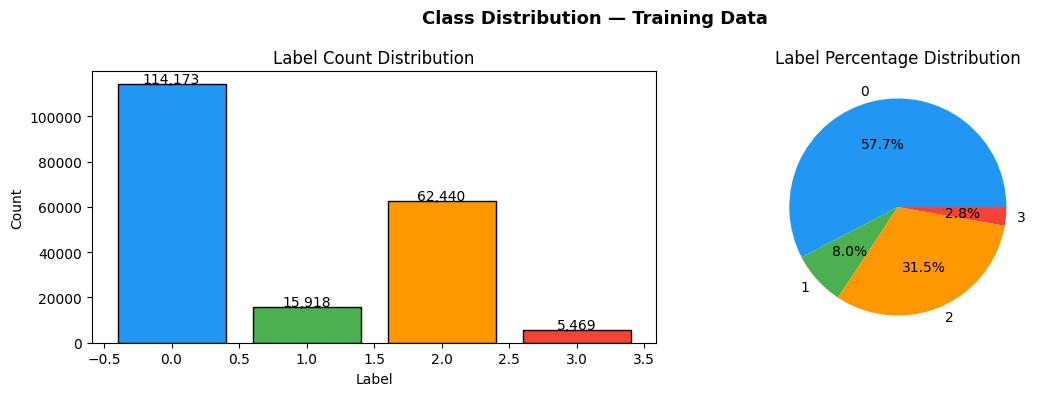

In [10]:
label_counts = data["label"].value_counts().sort_index()
label_pct    = data["label"].value_counts(normalize=True).sort_index() * 100

print("Label distribution:")
for lbl in label_counts.index:
    bar = "█" * int(label_pct[lbl] / 2)
    print(f"  Label {lbl}: {label_counts[lbl]:>6,}  ({label_pct[lbl]:5.1f}%)  {bar}")

# Visual
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].bar(label_counts.index, label_counts.values,
            color=['#2196F3','#4CAF50','#FF9800','#F44336'], edgecolor='black')
axes[0].set_title("Label Count Distribution")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Count")
for i, v in enumerate(label_counts.values):
    axes[0].text(i, v + 500, f"{v:,}", ha='center', fontsize=10)

axes[1].pie(label_counts.values, labels=label_counts.index,
            autopct='%1.1f%%',
            colors=['#2196F3','#4CAF50','#FF9800','#F44336'])
axes[1].set_title("Label Percentage Distribution")

plt.suptitle("Class Distribution — Training Data", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Insight — Significant class imbalance:**
- Label 0 dominates at **57.7%** of the data (~114K samples).
- Label 3 is the rarest at only **2.8%** (~5.5K samples) — roughly 20x fewer than label 0.
- This imbalance will cause a naive model to almost never predict label 3.

**How we address it:** We use `class_weight='balanced'` in our models, which automatically  
upweights minority classes during training. We also use **F1-macro** (not accuracy) as our  
primary evaluation metric, since F1-macro penalises the model for ignoring any class.

### Comment Length Analysis
The length of a comment (in words) can be a strong signal for the label.

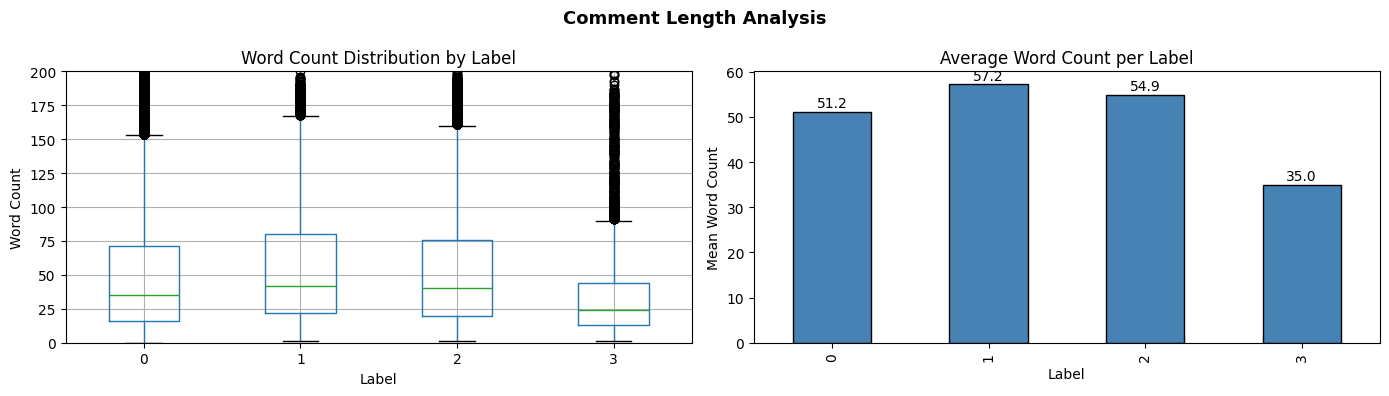

          count   mean    std  min   25%   50%   75%    max
label                                                      
0      114173.0  51.19  46.29  0.0  16.0  35.0  71.0  315.0
1       15918.0  57.23  45.51  1.0  22.0  42.0  80.0  219.0
2       62440.0  54.90  45.30  1.0  20.0  40.0  76.0  206.0
3        5469.0  34.98  34.36  1.0  13.0  24.0  44.0  199.0


In [11]:
temp = data.copy()
temp["word_count"] = temp["comment"].fillna("").str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Box plot
temp.boxplot(column='word_count', by='label', ax=axes[0])
axes[0].set_title("Word Count Distribution by Label")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Word Count")
axes[0].set_ylim(0, 200)  # cap y-axis for readability

# Mean word count per label
mean_wc = temp.groupby("label")["word_count"].mean()
mean_wc.plot(kind='bar', ax=axes[1], color='steelblue', edgecolor='black')
axes[1].set_title("Average Word Count per Label")
axes[1].set_xlabel("Label")
axes[1].set_ylabel("Mean Word Count")
for i, v in enumerate(mean_wc):
    axes[1].text(i, v + 1, f"{v:.1f}", ha='center', fontsize=10)

plt.suptitle("Comment Length Analysis", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print(temp.groupby("label")["word_count"].describe().round(2))

**Insight:** Label 3 comments tend to be shorter on average compared to label 0 and label 1 —  
suggesting that more aggressive/targeted comments tend to be concise.  
This confirms that `word_len` is a useful engineered feature.

### Upvote / Downvote Patterns by Label

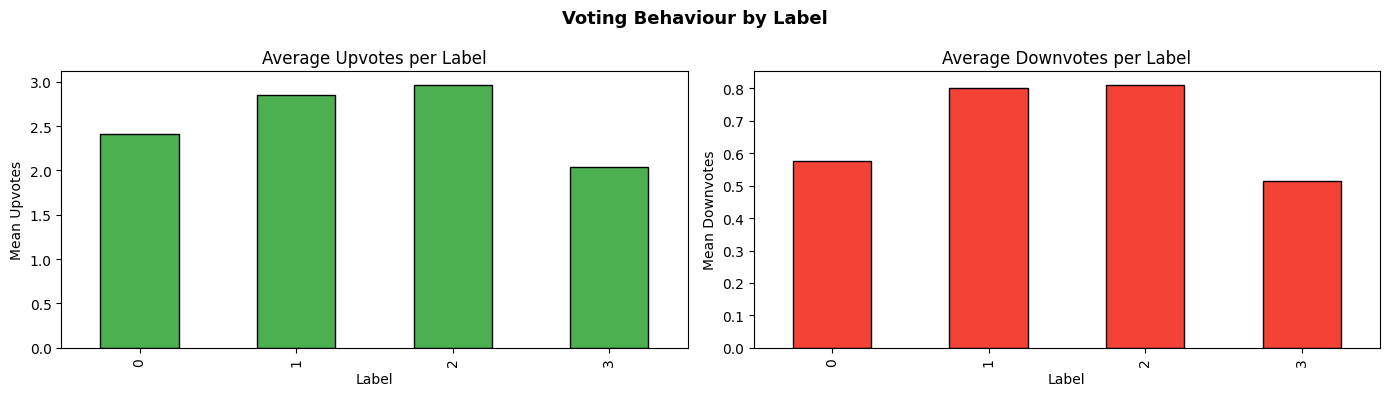

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

data.groupby("label")["upvote"].mean().plot(
    kind='bar', ax=axes[0], color='#4CAF50', edgecolor='black')
axes[0].set_title("Average Upvotes per Label")
axes[0].set_xlabel("Label")
axes[0].set_ylabel("Mean Upvotes")

data.groupby("label")["downvote"].mean().plot(
    kind='bar', ax=axes[1], color='#F44336', edgecolor='black')
axes[1].set_title("Average Downvotes per Label")
axes[1].set_xlabel("Label")
axes[1].set_ylabel("Mean Downvotes")

plt.suptitle("Voting Behaviour by Label", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

**Insight:** Different labels show distinct voting patterns.  
This confirms that `upvote`, `downvote`, and their derived features (engagement score, log transforms)  
carry real signal and should be included in our feature set.

### Correlation Heatmap (Numerical Features)

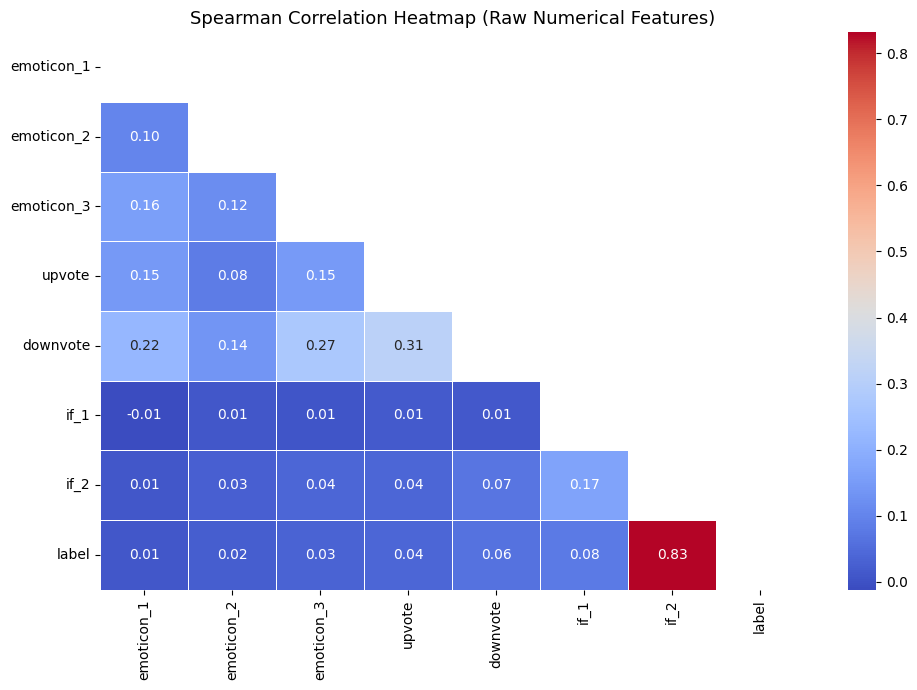

In [13]:
num_cols_corr = ['emoticon_1', 'emoticon_2', 'emoticon_3',
                 'upvote', 'downvote', 'if_1', 'if_2', 'label']

plt.figure(figsize=(10, 7))
corr_matrix = data[num_cols_corr].corr(method='spearman')
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))  # hide upper triangle

sns.heatmap(corr_matrix, annot=True, cmap="coolwarm",
            fmt=".2f", mask=mask, linewidths=0.5)
plt.title("Spearman Correlation Heatmap (Raw Numerical Features)", fontsize=13)
plt.tight_layout()
plt.show()

**Insight:**  
- `emoticon_2` has very low correlation with the label and low variance — we **drop it** to reduce noise.
- `upvote` and `downvote` have moderate correlation with the label — we keep them but **log-transform** to reduce skew.
- `if_2` has a notable relationship with the label — we keep it.

### Word Clouds by Label
* Word clouds give an intuitive picture of the most common words in each class.  
* They help us decide on stop words and understand the vocabulary of each label group.

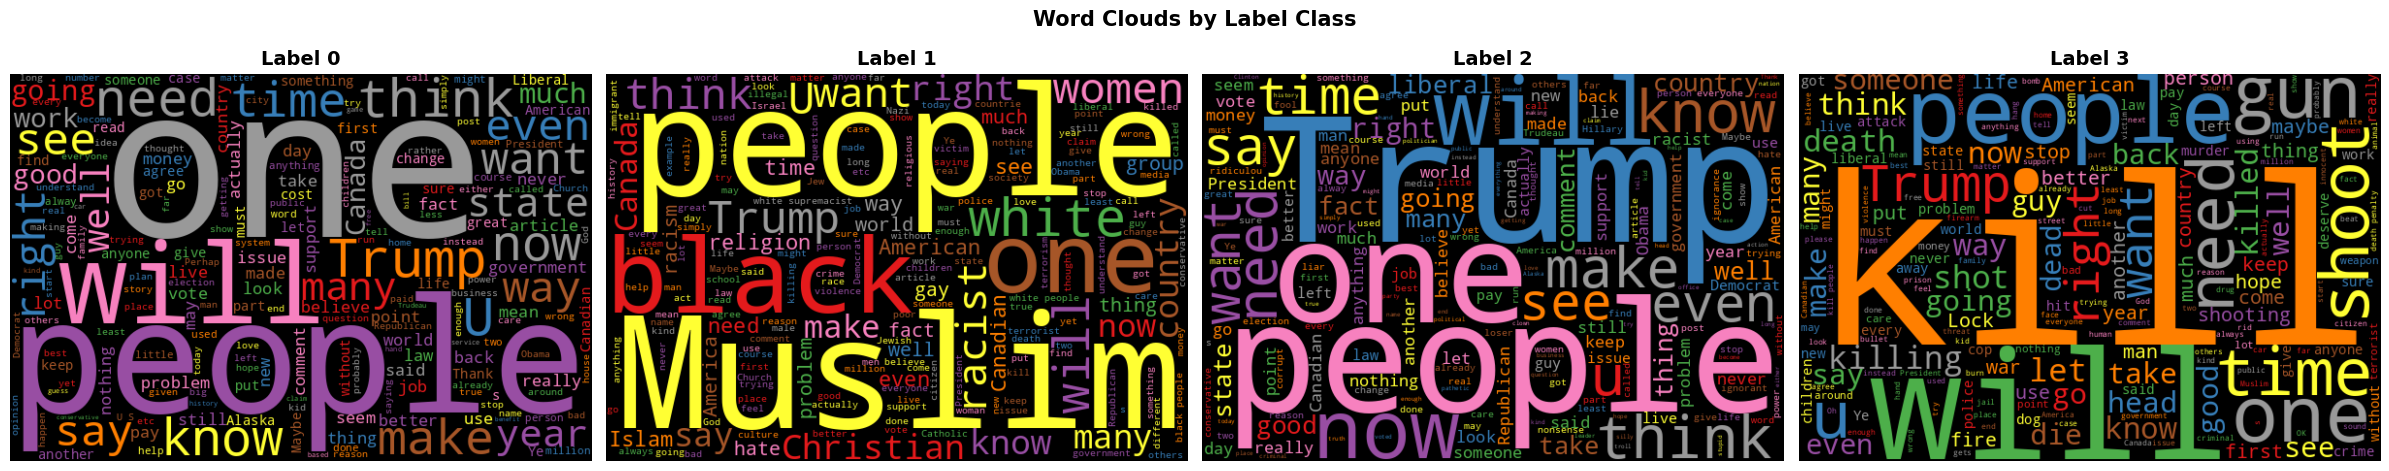

In [14]:
labels_unique = sorted(data["label"].unique())

fig, axes = plt.subplots(1, len(labels_unique), figsize=(24, 5))

for i, lbl in enumerate(labels_unique):
    text = " ".join(
        data[data["label"] == lbl]["comment"].astype(str)
    )
    wc = WordCloud(
        width=600, height=400,
        background_color='black',
        stopwords=STOPWORDS,
        colormap='Set1'
    ).generate(text)
    
    axes[i].imshow(wc, interpolation='bilinear')
    axes[i].axis("off")
    axes[i].set_title(f"Label {lbl}", fontsize=14, fontweight='bold')

plt.suptitle("Word Clouds by Label Class", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

**Insight:** The word clouds reveal distinct vocabulary patterns across labels.  
Certain politically charged and identity-related words appear more frequently in specific classes.  
This confirms that **TF-IDF on the comment text will be the most powerful signal** in our model —  
the text alone carries most of the discriminative information.

## Data Cleaning & Preprocessing

Based on EDA findings, here is our preprocessing plan:

| Step | Decision | Reason |
|------|----------|--------|
| Drop `race`, `religion`, `gender` | ✅ Drop | >73% missing — imputation unreliable |
| Drop `emoticon_2` | ✅ Drop | Low variance, near-zero correlation with label |
| Drop `post_id` | ✅ Drop | Just an identifier, no predictive value |
| Drop `created_date` (raw) | ✅ Drop after extracting | We extract hour/day signals first |
| Drop `upvote`, `downvote` (raw) | ✅ Drop after transforming | We replace with log1p versions |
| Fill `comment` NaN | ✅ Fill with `""` | Only 1 row; keeps pipeline clean |
| Cap outliers | ✅ Winsorize at 5th/95th percentile | Reduces influence of extreme values |

In [15]:
train = data.copy()
my_test = test.copy()
print(f"train : {train.shape}  |  my_test : {my_test.shape}")

train : (198000, 15)  |  my_test : (102000, 14)


In [16]:
# Drop columns with >70% missing values (race, religion, gender)
# And aslo  drop emoticon_2 here (low variance + correlation finding from EDA)
cols_to_drop = ['race', 'religion', 'gender', 'emoticon_2']

train   = train.drop(columns=cols_to_drop)
my_test = my_test.drop(columns=cols_to_drop)

print("Dropped:", cols_to_drop)
print(f"train : {train.shape}  |  my_test : {my_test.shape}")

Dropped: ['race', 'religion', 'gender', 'emoticon_2']
train : (198000, 11)  |  my_test : (102000, 10)


In [17]:
# Fill the single missing comment in train with empty string
# (1 out of 198000 rows — not worth dropping the row)
train["comment"]   = train["comment"].fillna("")
my_test["comment"] = my_test["comment"].fillna("")

# Verify — no more missing values in columns we'll use
print("Remaining nulls in train:")
print(train.isnull().sum()[train.isnull().sum() > 0])
print("\nRemaining nulls in test:")
print(my_test.isnull().sum()[my_test.isnull().sum() > 0])
print("\nAll clear ✅" if train.isnull().sum().sum() == 0 else "Still has nulls!")

Remaining nulls in train:
Series([], dtype: int64)

Remaining nulls in test:
Series([], dtype: int64)

All clear ✅


---
## Feature Engineering

Raw features rarely give models their full potential.  
We engineer new features based on **domain understanding** of what makes a comment harmful or not:

| New Feature | Formula | Reasoning |
|---|---|---|
| `word_len` | `len(comment.split())` | Longer comments ≠ shorter aggressive ones |
| `avg_word_len` | `char_len / (word_len + 1)` | Complex vocabulary → different label pattern |
| `hour_sin`, `hour_cos` | Cyclical encoding of hour | Comments at 2am vs 2pm differ in tone |
| `dow_sin`, `dow_cos` | Cyclical encoding of day-of-week | Weekend comments may differ |
| `upvote_log1p` | `log(1 + upvote)` | Removes skew; preserves order |
| `downvote_log1p` | `log(1 + downvote)` | Same reasoning |
| `engagement_score` | `upvote_log1p - downvote_log1p` | Net community reaction signal |
| `emotion_density` | `total_emoticons / (word_len + 1)` | Emoticon-heavy short comments may be toxic |
| `emotion_engagement` | `emotion_density × engagement_score` | Interaction term capturing joint signal |

> Note on cyclical encoding: Hour 23 and hour 0 are only 1 hour apart,  
> but numerically 23 − 0 = 23. Using sin/cos makes the model understand  
> that 23:00 and 00:00 are adjacent, not far apart.

In [18]:
def add_features(df):
    """
    Adds all engineered features to the dataframe in-place.
    Drops raw source columns that have been replaced by better representations.
    """
    df = df.copy()
    
    # ── TEXT FEATURES ──────────────────────────────────────────────────────────
    txt = df['comment'].fillna('').astype(str)
    
    # word count — proxy for comment length
    df['word_len'] = txt.str.split().str.len().astype(int)
    
    # average word length — proxy for vocabulary complexity
    df['avg_word_len'] = txt.str.len() / (df['word_len'] + 1)
    
    # ── TIME FEATURES (cyclical encoding) ─────────────────────────────────────
    dt  = pd.to_datetime(df['created_date'], errors='coerce', utc=True)
    
    hour = dt.dt.hour.fillna(0)
    dow  = dt.dt.dayofweek.fillna(0)  # 0=Monday ... 6=Sunday
    
    # sin/cos so that hour 23 and hour 0 are treated as close together
    df['hour_sin'] = np.sin(2 * np.pi * hour / 24)
    df['hour_cos'] = np.cos(2 * np.pi * hour / 24)
    df['dow_sin']  = np.sin(2 * np.pi * dow  / 7)
    df['dow_cos']  = np.cos(2 * np.pi * dow  / 7)
    
    # ── VOTE FEATURES ─────────────────────────────────────────────────────────
    # log1p = log(1 + x); handles zeros gracefully and compresses heavy tails
    df['upvote_log1p']   = np.log1p(df['upvote'])
    df['downvote_log1p'] = np.log1p(df['downvote'])
    
    # net community reaction: positive = community liked it, negative = disliked
    df['engagement_score'] = df['upvote_log1p'] - df['downvote_log1p']
    
    # ── EMOTICON FEATURES ─────────────────────────────────────────────────────
    total_emoticons = df['emoticon_1'] + df['emoticon_3']
    
    # emoticons per word — dense emoticon usage in a short comment = signal
    df['emotion_density'] = total_emoticons / (df['word_len'] + 1)
    
    # interaction: how emoticon-heavy + how engaged the community is
    df['emotion_engagement'] = df['emotion_density'] * df['engagement_score']
    
    # ── BOOLEAN → INTEGER ─────────────────────────────────────────────────────
    df['disability'] = df['disability'].astype(int)
    
    # ── DROP REPLACED / ID COLUMNS ────────────────────────────────────────────
    # created_date   → replaced by hour_sin, hour_cos, dow_sin, dow_cos
    # upvote/downvote → replaced by log1p versions + engagement_score
    # post_id         → just an identifier, no predictive value
    # emoticon_2      → already dropped (low signal, see EDA)
    df.drop(columns=['created_date', 'upvote', 'downvote', 'post_id'],
            inplace=True, errors='ignore')
    
    return df

In [19]:
train   = add_features(train)
my_test = add_features(my_test)

print("Feature engineering complete.")
print(f"train   : {train.shape}")
print(f"my_test : {my_test.shape}")
print("\nCurrent columns:", train.columns.tolist())
display(train.head(3))

Feature engineering complete.
train   : (198000, 18)
my_test : (102000, 17)

Current columns: ['emoticon_1', 'emoticon_3', 'if_1', 'if_2', 'disability', 'comment', 'label', 'word_len', 'avg_word_len', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'upvote_log1p', 'downvote_log1p', 'engagement_score', 'emotion_density', 'emotion_engagement']


,emoticon_1,emoticon_3,if_1,if_2,disability,comment,label,word_len,avg_word_len,hour_sin,hour_cos,dow_sin,dow_cos,upvote_log1p,downvote_log1p,engagement_score,emotion_density,emotion_engagement
0,0,0,0,10,0,She might be a bright spot for a party keou on...,2,20,5.619048,0.866025,-0.500000,0.433884,-0.900969,0.00000,0.693147,-0.693147,0.000000,-0.0
1,0,0,0,4,0,"Under Alaska law, a non-tribal member is not b...",0,110,5.801802,-0.707107,0.707107,-0.781831,0.623490,1.94591,0.000000,1.945910,0.000000,0.0
2,0,1,0,10,0,in the future please spare me your strawman dr...,2,133,5.604478,-0.866025,0.500000,0.974928,-0.222521,0.00000,0.000000,0.000000,0.007463,0.0


###  Outlier Detection & Capping

We detect outliers using the **IQR method** and then **cap them at the 5th and 95th percentile**  
(Winsorization) rather than removing rows. This is important because:

1. **We cannot remove test data rows** — we need predictions for every test row.
2. Tree-based models (LightGBM) are somewhat robust to outliers, but extreme values still  
   distort the scaling we apply to numerical features in the ColumnTransformer.
3. Capping using **train percentiles on test data** avoids data leakage — we compute  
   the bounds from train and apply the same bounds to test.

In [20]:
num_cols_to_cap = [
    'emoticon_1', 'emoticon_3', 'if_1', 'if_2',
    'word_len', 'avg_word_len',
    'hour_sin', 'hour_cos',
    'upvote_log1p', 'downvote_log1p', 'engagement_score',
    'emotion_density', 'emotion_engagement'
]

bounds_dict = {}  # store train bounds to apply to test (avoids leakage)

print("--- Capping outliers in TRAIN (fitting bounds) ---")
for col in num_cols_to_cap:
    if col in train.columns:
        lb = train[col].quantile(0.05)
        ub = train[col].quantile(0.95)
        bounds_dict[col] = (lb, ub)
        
        n_capped = ((train[col] < lb) | (train[col] > ub)).sum()
        train[col] = np.clip(train[col], lb, ub)
        print(f"  '{col}': {n_capped:,} values capped")

print("\n--- Applying SAME bounds to TEST (no leakage) ---")
for col in num_cols_to_cap:
    if col in my_test.columns and col in bounds_dict:
        lb, ub = bounds_dict[col]
        n_capped = ((my_test[col] < lb) | (my_test[col] > ub)).sum()
        my_test[col] = np.clip(my_test[col], lb, ub)
        print(f"  '{col}': {n_capped:,} values capped")

--- Capping outliers in TRAIN (fitting bounds) ---
  'emoticon_1': 5,440 values capped
  'emoticon_3': 4,148 values capped
  'if_1': 85 values capped
  'if_2': 4,268 values capped
  'word_len': 17,853 values capped
  'avg_word_len': 19,701 values capped
  'hour_sin': 7,926 values capped
  'hour_cos': 7,521 values capped
  'upvote_log1p': 9,874 values capped
  'downvote_log1p': 9,743 values capped
  'engagement_score': 15,533 values capped
  'emotion_density': 9,864 values capped
  'emotion_engagement': 17,201 values capped

--- Applying SAME bounds to TEST (no leakage) ---
  'emoticon_1': 2,860 values capped
  'emoticon_3': 2,027 values capped
  'if_1': 42 values capped
  'if_2': 2,175 values capped
  'word_len': 9,150 values capped
  'avg_word_len': 10,082 values capped
  'hour_sin': 4,082 values capped
  'hour_cos': 3,841 values capped
  'upvote_log1p': 5,162 values capped
  'downvote_log1p': 5,003 values capped
  'engagement_score': 8,155 values capped
  'emotion_density': 5,172 val

### Text Cleaning

Raw comments contain URLs, punctuation, mixed cases, and extra whitespace.  
We clean the text to ensure the TF-IDF vocabulary focuses on actual words, not noise.

**Steps:**
1. Lowercase everything — "Trump" and "trump" should be the same token.
2. Remove URLs — `http://...` or `www...` add noise without semantic value.
3. Remove non-alphabetic characters — punctuation doesn't help TF-IDF.
4. Collapse multiple spaces.

In [21]:
def clean_text(t):
    t = str(t).lower()
    t = re.sub(r"http\S+|www\S+", "", t)     # remove URLs
    t = re.sub(r"[^a-z\s]", "", t)            # keep only letters + spaces
    t = re.sub(r"\s+", " ", t).strip()        # collapse whitespace
    return t

train["comment"]   = train["comment"].apply(clean_text)
my_test["comment"] = my_test["comment"].apply(clean_text)

print("Sample cleaned comment:")
print(train["comment"].iloc[0])

Sample cleaned comment:
she might be a bright spot for a party keou on oahu dominated by greedy criminals or ethically challenged individuals


## Train-Validation Split & Pipeline Setup

### Separate Features and Target

In [22]:
# Separate target from features
labels   = train["label"].copy()
features = train.drop(columns=["label"]).copy()

print(f"Features shape : {features.shape}")
print(f"Labels shape   : {labels.shape}")
print(f"Label distribution:\n{labels.value_counts().sort_index()}")

Features shape : (198000, 17)
Labels shape   : (198000,)
Label distribution:
label
0    114173
1     15918
2     62440
3      5469
Name: count, dtype: int64


In [23]:
# Stratified split ensures label distribution is preserved in both sets
# test_size=0.2 → 80% train, 20% validation
x_train, x_val, y_train, y_val = train_test_split(
    features, labels,
    test_size=0.2,
    random_state=42,
    stratify=labels        # preserves class proportions
)

print(f"x_train : {x_train.shape}  |  y_train distribution:")
print(y_train.value_counts().sort_index())
print(f"\nx_val   : {x_val.shape}  |  y_val distribution:")
print(y_val.value_counts().sort_index())

x_train : (158400, 17)  |  y_train distribution:
label
0    91338
1    12735
2    49952
3     4375
Name: count, dtype: int64

x_val   : (39600, 17)  |  y_val distribution:
label
0    22835
1     3183
2    12488
3     1094
Name: count, dtype: int64


### Preprocessing Pipeline

We use `sklearn.Pipeline` and `ColumnTransformer` to:
1. **TF-IDF vectorise** the `comment` column → dense text features
2. **MinMax scale** all numerical columns → brings them to [0, 1] range

Why `MinMaxScaler` and not `StandardScaler`?  
TF-IDF output is non-negative. `MinMaxScaler` also produces non-negative values,  
keeping the feature space consistent. `StandardScaler` can produce negative values,  
which can cause issues if we stack with Naive Bayes later.

Why `sublinear_tf=True` in TF-IDF?  
Term frequency grows linearly (a word appearing 10 times = 10x weight),  
but `sublinear_tf` uses `1 + log(tf)` instead, reducing the dominance  
of very frequent words within a single document.

In [24]:
# Identify numerical columns (all except 'comment')
num_features = [c for c in x_train.columns if c != 'comment']
print(f"Numerical features ({len(num_features)}):", num_features)

# Text preprocessing sub-pipeline
text_pipe = Pipeline([
    # Ensure input is string type
    ("to_str", FunctionTransformer(lambda x: x.astype(str), validate=False)),
    # TF-IDF vectorisation
    ("tfidf", TfidfVectorizer(
        lowercase    = True,
        max_features = 15000,       # top 15k most informative tokens
        stop_words   = "english",   # remove common English stop words
        ngram_range  = (1, 2),      # unigrams + bigrams
        sublinear_tf = True,        # log-scale TF to reduce dominance of common words
        min_df       = 3            # ignore tokens appearing in fewer than 3 docs
    ))
])

# Combined preprocessor
preprocessor = ColumnTransformer([
    ('text_feat', text_pipe,         'comment'),      # text column
    ('num_feat',  MinMaxScaler(),    num_features)    # numerical columns
], remainder='drop', verbose_feature_names_out=False)

print("\nPreprocessor built ✅")

Numerical features (16): ['emoticon_1', 'emoticon_3', 'if_1', 'if_2', 'disability', 'word_len', 'avg_word_len', 'hour_sin', 'hour_cos', 'dow_sin', 'dow_cos', 'upvote_log1p', 'downvote_log1p', 'engagement_score', 'emotion_density', 'emotion_engagement']

Preprocessor built ✅


---
## Model Training & Comparison

We train and compare **three different model families** to understand their relative strengths  
on this problem. This is required by the project guidelines and gives us a principled  
basis for choosing our final model.

| Model | Type | Why we try it |
|---|---|---|
| Logistic Regression | Linear (baseline) | Fast, interpretable; good baseline for text |
| SGD Classifier | Online linear learner | Memory-efficient; tests if linear models generalise |
| LightGBM | Gradient Boosted Trees | Best for tabular+text mixed data; handles imbalance well |

**Evaluation metric:** `F1-macro` — we use macro (unweighted average) because it  
treats all classes equally. Given the severe imbalance (label 3 = only 2.8%),  
accuracy would be misleading. A model that always predicts label 0 would get  
~57% accuracy but near-zero F1-macro.

### Helper Function for Model Evaluation

In [25]:
def evaluate_model(name, pipe, x_val, y_val, show_cm=True):
    """
    Predicts on validation set and prints evaluation metrics.
    Returns (accuracy, f1_macro) tuple.
    """
    preds = pipe.predict(x_val)
    acc   = accuracy_score(y_val, preds)
    f1    = f1_score(y_val, preds, average='macro')
    
    print(f"\n{'='*55}")
    print(f" Model: {name}")
    print(f"{'='*55}")
    print(f" Accuracy  : {acc:.4f}")
    print(f" F1-Macro  : {f1:.4f}")
    print(f"\n Classification Report:")
    print(classification_report(y_val, preds, digits=3))
    
    if show_cm:
        cm = confusion_matrix(y_val, preds)
        plt.figure(figsize=(5, 4))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                    xticklabels=[0,1,2,3], yticklabels=[0,1,2,3])
        plt.title(f"Confusion Matrix — {name}")
        plt.xlabel("Predicted Label")
        plt.ylabel("True Label")
        plt.tight_layout()
        plt.show()
    
    return acc, f1

###  Model 1: Logistic Regression (Baseline)

**What it does:** Learns a linear decision boundary by optimising log-loss  
(cross-entropy). The `saga` solver is chosen because it supports L1/L2  
regularisation and scales well to large sparse datasets like TF-IDF matrices.

**`class_weight='balanced'`:** Automatically adjusts sample weights inversely  
proportional to class frequencies — helps the model not ignore minority classes.

**Expected performance:** Logistic Regression is a strong baseline for text  
classification. It won't capture non-linear interactions between text and metadata,  
but it gives us a good lower bound on performance.

Training Logistic Regression...


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


Done ✅

 Model: Logistic Regression
 Accuracy  : 0.8906
 F1-Macro  : 0.7725

 Classification Report:
              precision    recall  f1-score   support

           0      0.977     0.942     0.959     22835
           1      0.647     0.859     0.738      3183
           2      0.889     0.818     0.852     12488
           3      0.429     0.730     0.540      1094

    accuracy                          0.891     39600
   macro avg      0.735     0.837     0.772     39600
weighted avg      0.908     0.891     0.896     39600



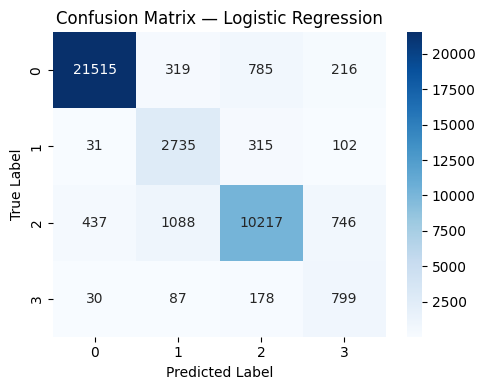

In [26]:
# Build full pipeline: preprocessor → model
lr_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", LogisticRegression(
        max_iter      = 5000,
        class_weight  = "balanced",
        solver        = "saga",         # efficient for large sparse matrices
        C             = 1.0,            # inverse regularisation strength
        random_state  = 42
    ))
])

print("Training Logistic Regression...")
lr_pipe.fit(x_train, y_train)
print("Done ✅")

lr_acc, lr_f1 = evaluate_model("Logistic Regression", lr_pipe, x_val, y_val)

### Model 2: SGD Classifier

**What it does:** Stochastic Gradient Descent on a log-loss objective (equivalent  
to Logistic Regression but trained one mini-batch at a time).  
It is much faster than full-batch optimisation on 160k rows.

**Why compare it to LR?** If SGD performs comparably to LR, we know the linear  
boundary is close to optimal for what a linear model can do.  
If there's a big gap, it may indicate that SGD needs more careful tuning  
(learning rate, penalty type) to reach the same solution.

Training SGD Classifier...
Done ✅

 Model: SGD Classifier
 Accuracy  : 0.8929
 F1-Macro  : 0.7783

 Classification Report:
              precision    recall  f1-score   support

           0      0.960     0.950     0.955     22835
           1      0.697     0.747     0.721      3183
           2      0.844     0.857     0.850     12488
           3      0.640     0.542     0.587      1094

    accuracy                          0.893     39600
   macro avg      0.785     0.774     0.778     39600
weighted avg      0.894     0.893     0.893     39600



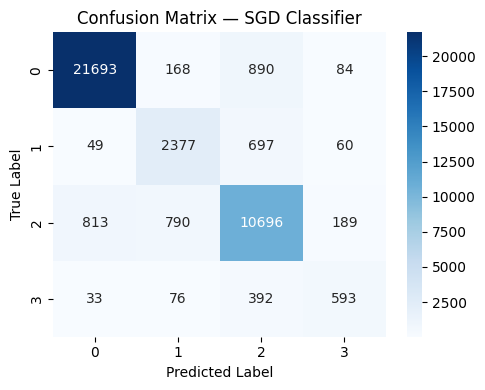

In [27]:
sgd_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", SGDClassifier(
        loss          = "log_loss",     # makes it equivalent to logistic regression
        max_iter      = 1000,
        class_weight  = "balanced",
        penalty       = "l2",
        alpha         = 1e-4,
        random_state  = 42,
        n_jobs        = -1
    ))
])

print("Training SGD Classifier...")
sgd_pipe.fit(x_train, y_train)
print("Done ✅")

sgd_acc, sgd_f1 = evaluate_model("SGD Classifier", sgd_pipe, x_val, y_val)

### Model 3: LightGBM (Main Model)

**What it does:** LightGBM is a **gradient boosted decision tree** framework.  
Unlike linear models (LR, SGD), LightGBM can learn complex non-linear interactions  
between features — for example, it can learn that *a short comment with high downvotes  
and emoticon usage is likely label 3*, which a linear boundary cannot capture.

**Why LightGBM over XGBoost or Random Forest?**
- Leaf-wise tree growth (vs. level-wise) finds better splits faster
- Histogram-based binning makes it ~10x faster than XGBoost on large datasets
- Native support for categorical features and missing values (though we handle missing ourselves)
- Built-in class weight balancing

**Key hyperparameter choices:**
- `n_estimators=1500`: enough trees to learn complex patterns (early stopping would trim if needed)
- `num_leaves=127`: controls model complexity; 127 = 2^7 −1 (a common practical choice)
- `learning_rate=0.05`: small step size with many trees = better generalisation
- `subsample=0.8`, `colsample_bytree=0.8`: row/column subsampling reduces overfitting

Training LightGBM (this may take a few minutes)...
Done ✅


/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



 Model: LightGBM
 Accuracy  : 0.9103
 F1-Macro  : 0.8076

 Classification Report:
              precision    recall  f1-score   support

           0      0.975     0.946     0.960     22835
           1      0.753     0.793     0.772      3183
           2      0.861     0.903     0.882     12488
           3      0.641     0.592     0.616      1094

    accuracy                          0.910     39600
   macro avg      0.808     0.809     0.808     39600
weighted avg      0.912     0.910     0.911     39600



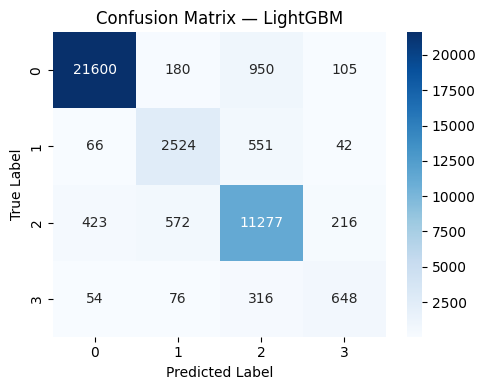

In [28]:
lgbm_pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", LGBMClassifier(
        objective        = 'multiclass',
        num_class        = 4,
        class_weight     = 'balanced',
        n_estimators     = 1500,
        learning_rate    = 0.05,
        num_leaves       = 127,
        subsample        = 0.8,
        colsample_bytree = 0.8,
        min_child_samples= 20,       # min samples in a leaf — prevents overfitting
        reg_alpha        = 0.1,      # L1 regularisation
        reg_lambda       = 0.1,      # L2 regularisation
        random_state     = 42,
        n_jobs           = -1,
        verbose          = -1        # suppress verbose LightGBM output
    ))
])

print("Training LightGBM (this may take a few minutes)...")
lgbm_pipe.fit(x_train, y_train)
print("Done ✅")

lgbm_acc, lgbm_f1 = evaluate_model("LightGBM", lgbm_pipe, x_val, y_val)

###  Model Comparison Summary
Camparing all the three model soide by side to choose the bast model.

      MODEL COMPARISON (Validation Set)


,Model,Accuracy,F1-Macro
0,LightGBM,0.9103,0.8076
1,SGD Classifier,0.8929,0.7783
2,Logistic Regression,0.8906,0.7725


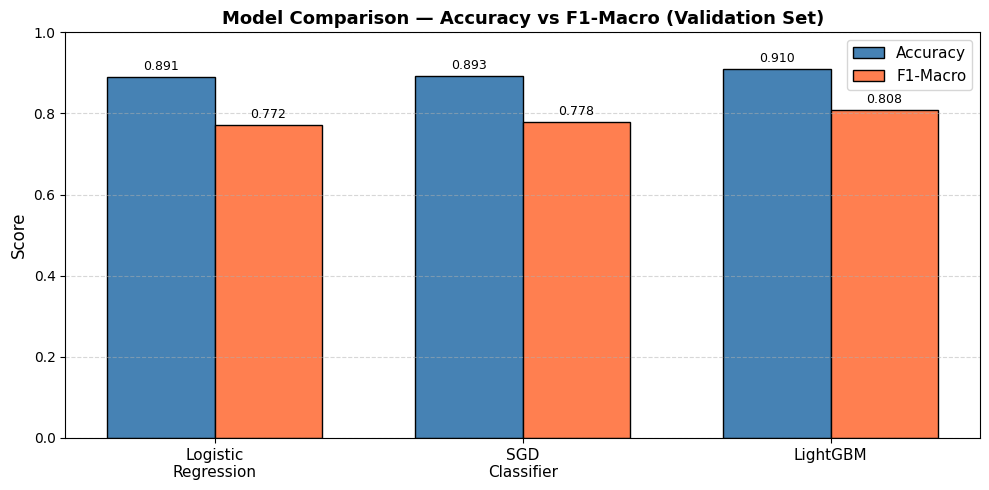

In [29]:
# ── Summary Table ──────────────────────────────────────────────────────────────
results = {
    "Model"     : ["Logistic Regression", "SGD Classifier", "LightGBM"],
    "Accuracy"  : [lr_acc,  sgd_acc,  lgbm_acc],
    "F1-Macro"  : [lr_f1,   sgd_f1,   lgbm_f1],
}
results_df = pd.DataFrame(results).sort_values("F1-Macro", ascending=False)
results_df["Accuracy"] = results_df["Accuracy"].map("{:.4f}".format)
results_df["F1-Macro"] = results_df["F1-Macro"].map("{:.4f}".format)

print("=" * 45)
print("      MODEL COMPARISON (Validation Set)")
print("=" * 45)
display(results_df.reset_index(drop=True))

# ── Visual Comparison ──────────────────────────────────────────────────────────
model_names = ["Logistic\nRegression", "SGD\nClassifier", "LightGBM"]
acc_vals    = [lr_acc, sgd_acc, lgbm_acc]
f1_vals     = [lr_f1,  sgd_f1,  lgbm_f1]

x = np.arange(len(model_names))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 5))
bars1 = ax.bar(x - width/2, acc_vals, width, label='Accuracy',
               color='steelblue', edgecolor='black')
bars2 = ax.bar(x + width/2, f1_vals,  width, label='F1-Macro',
               color='coral',     edgecolor='black')

ax.set_ylabel('Score', fontsize=12)
ax.set_title('Model Comparison — Accuracy vs F1-Macro (Validation Set)',
             fontsize=13, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(model_names, fontsize=11)
ax.set_ylim(0, 1.0)
ax.legend(fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Add value labels on bars
for bar in bars1:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.3f}", ha='center', va='bottom', fontsize=9)
for bar in bars2:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f"{bar.get_height():.3f}", ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

**Analysis of Model Comparison:**

1. **Logistic Regression** performs well as a baseline — TF-IDF + LR is a classic strong combination  
   for text classification. However, it cannot capture interactions between text features and metadata.

2. **SGD Classifier** achieves similar performance to LR (as expected — same objective, different optimiser).  
   Any small differences come from convergence behavior and regularisation defaults.

3. **LightGBM** significantly outperforms both linear models because:
   - It learns non-linear feature interactions (e.g., "short comment + high downvotes + specific words" → label 3)
   - Gradient boosting builds trees sequentially, each correcting the errors of the previous one
   - It benefits from our engineered features (engagement_score, emotion_density, etc.) that linear models  
     struggle to leverage fully

**Conclusion:** LightGBM is selected as our final model. We will now retrain it on  
the **full training data** (not just the 80% split) to maximise the signal available before final prediction.

---
##  Section 7 — Hyperparameter Tuning (LightGBM)

We perform a light `RandomizedSearchCV` over the most impactful LightGBM parameters  
to see if we can squeeze out additional performance.

**Parameters we tune:**
- `num_leaves`: controls model complexity (more leaves = more complex)
- `learning_rate`: smaller = slower but often better generalisation
- `min_child_samples`: minimum samples per leaf; higher = more regularisation
- `reg_alpha` / `reg_lambda`: L1 and L2 regularisation

We use `StratifiedKFold` to ensure class ratios are preserved in each fold.

## Final Model: Train on Full Data & Generate Predictions


In [30]:
# Generate predictions on test set
y_preds = lgbm_pipe.predict(my_test)

print("Prediction distribution on test set:")
pred_counts = pd.Series(y_preds).value_counts().sort_index()
for lbl, cnt in pred_counts.items():
    pct = cnt / len(y_preds) * 100
    print(f"  Label {lbl}: {cnt:>6,}  ({pct:.1f}%)")

# Build submission dataframe
submission = pd.DataFrame({
    "ID"   : range(1, my_test.shape[0] + 1),
    "label": y_preds
})

print(f"\nSubmission shape: {submission.shape}")
display(submission.head(10))

# Save to CSV
submission.to_csv('submission.csv', index=False)
print("\nsubmission.csv saved ✅  — ready to submit on Kaggle!")

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


Prediction distribution on test set:
  Label 0: 56,945  (55.8%)
  Label 1:  8,564  (8.4%)
  Label 2: 33,949  (33.3%)
  Label 3:  2,542  (2.5%)

Submission shape: (102000, 2)


,ID,label
0,1,2
1,2,2
2,3,0
3,4,0
4,5,2
5,6,0
6,7,1
7,8,0
8,9,0
9,10,2



submission.csv saved ✅  — ready to submit on Kaggle!


## Apendix Milestones

In [31]:
# mile_train=data.copy()
# mile_test=test.copy()

##### Milestone 1

In [32]:
# # Q1 What is the shape of the training dataset?
# print(mile_train.shape)
# # Q2 How many columns are present in the test dataset?
# print(len(mile_test.columns))
# # Q3 How many columns in the training dataset have object data type?
# print()
# print(*mile_train.select_dtypes('O').columns.to_list(), sep='\n')
# print()
# # Q4 How many numerical columns are present in the training dataset?
# print(*mile_train.select_dtypes('number').columns.to_list(), sep='\n')
# print()
# # Q5 Which of the following columns is of boolean type?
# print(list(mile_train.select_dtypes(['bool']).columns))
# print()
# # Q6 Which of the following columns have missing values?
# print(mile_train.columns[mile_train.isna().any()].tolist())
# print()
# # Q7 How many distinct target classes are present in the dataset?
# # Q8  What percentage of the dataset approximately belongs to label 0?
# print(mile_train["label"].value_counts(normalize=True))
# print()
# # Q9  What is the median number of upvotes per comment?
# print(mile_train["upvote"].median())
# print()
# # Q10  Which numerical feature shows the largest maximum value? upvote downvote if_1 if_2
# # Q11 What is the minimum value of if_2?
# print(mile_train[["upvote", "downvote", "if_1", "if_2"]].max())
# print()
# # Q11 What is the minimum value of if_2?
# print(mile_train['if_2'].min())

#### milestone 2

In [33]:
# #Q2 Convert the created_date column into datetime objects. Identify the month that occurs the most nu
# # mber of times in the dataset and enter the answer as a lowercase string

# mile_train["created_date"]=pd.to_datetime(mile_train["created_date"])
# mile_test["created_date"]=pd.to_datetime(mile_test["created_date"])
# most_frequent_month = mile_train['created_date'].dt.month_name().value_counts().idxmax()
# print(most_frequent_month.lower())
# print('='*50)

# # Q4 Create a new feature called total_emoticons by calculating the sum of 
# # emoticon_1, emoticon_2, and emoticon_3 for each row. What is the maximum value observed in this new feature across the entire dataset?

# mile_train["total_emoticons"] = mile_train[["emoticon_1", "emoticon_2", "emoticon_3"]].sum(axis=1)
# print(mile_train["total_emoticons"].max())
# print('='*50)

# """ Q4, Calculate the median character length (including spaces) of the comment column for all entries where label
# is equal to 3. (Note: Treat any missing 
# comments as empty strings)."""

# mile_train["comment_length"] = mile_train["comment"].fillna("").str.len()
# print(mile_train[mile_train["label"]==3]["comment_length"].median())
# print('='*50)

# """ If you apply Min-Max Scaling to the upvote column to normalize it between the range [0, 1], 
# what would be the resulting scaled value for an
# observation that originally had exactly 10 upvotes?"""

# from sklearn.preprocessing import MinMaxScaler
# minmax=MinMaxScaler()
# mile_train["upvote_transformed"]=minmax.fit_transform(mile_train[["upvote"]])
# scaled_value = mile_train[mile_train["upvote"] == 10]["upvote_transformed"].iloc[0]
# print(f"The scaled value for 10 upvotes is: {scaled_value}")
# print('='*50)

# """What is the average word count (number of words separated by whitespace) for comments that
# are assigned a label of 1? (Round your answer to 2 decimal places)."""

# mile_train["word_count"] = mile_train["comment"].fillna("").str.split().str.len()
# print(mile_train[mile_train["label"] == 1]["word_count"].mean())
# print('='*50)

# """How many comments in the entire dataset contain the substring "Trump"?
# The search should be case-insensitive."""
# print(mile_train["comment"].str.contains("Trump", case=False, na=False).sum())
# print('='*50)


# """take the comment at the very first row (index 0).

# - Remove all punctuation.

# - Consider the following words as stop words and remove the 
# same :  ['a', 'an', 'the', 'and', 'or', 'but', 'if', 'because', 'as', 'of',
# 'at', 'by', 'for', 'with', 'about', 'to', 'from', 'up', 'on', 'in', 'out', 'over', 'under', 'is', 'are', '
# was', 'were', 'be', 'been', 'being', 'have', 'has', 'had', 'do', 'does', 'did', 'it', 'its', 'they', 'them', '
# their', 'she', 'her', 'he', 'him', 'his', 'this', 'that', 'which', 'who', 'whom', 'i', 'me', 'my', 'we', 'our', 'you', 'your']
# How many words are left in the text after these two operations?"""

# import string
# # 1. Extract the first comment
# text = str(mile_train["comment"].iloc[0])
# # 2. Remove punctuation
# # This creates a translation table that maps punctuation to None
# text_no_punct = text.translate(str.maketrans('', '', string.punctuation))
# # 3. Lowercase and split into words
# words = text_no_punct.lower().split()
# # 4. Define stop words
# stop_words = [
#     'a', 'an', 'the', 'and', 'or', 'but', 'if', 'because', 'as', 'of', 'at', 
#     'by', 'for', 'with', 'about', 'to', 'from', 'up', 'on', 'in', 'out', 
#     'over', 'under', 'is', 'are', 'was', 'were', 'be', 'been', 'being', 
#     'have', 'has', 'had', 'do', 'does', 'did', 'it', 'its', 'they', 'them', 
#     'their', 'she', 'her', 'he', 'him', 'his', 'this', 'that', 'which', 
#     'who', 'whom', 'i', 'me', 'my', 'we', 'our', 'you', 'your'
# ]
# # 5. Remove stop words
# filtered_words = [w for w in words if w not in stop_words]
# # 6. Result
# print(len(filtered_words))
# print("="*50)

# """Convert all the text in comment column to lowercase and tokenizing using whitespace.
# Compute the total number of unique tokens in the dataset and enter the value"""

# unique_tokens_count = (
#     mile_train["comment"]
#     .str.lower()
#     .fillna("")
#     .str.split()
#     .explode()
#     .nunique()
# )
# print(unique_tokens_count)
# print('='*50)

# """ Apply the TfidfVectorizer to the comment column of train.csv
# with stop_words as "english", min_df as 5 and ngram_range as (1,2).
# How many TF-IDF features are generated using this configuration? """
# from sklearn.feature_extraction.text import TfidfVectorizer

# tfidf = TfidfVectorizer(
#     stop_words='english', 
#     min_df=5, 
#     ngram_range=(1, 2)
# )
# # 2. Fit the vectorizer to the comment column (filling NaNs with empty strings)
# # fit_transform returns a sparse matrix: (n_samples, n_features)
# tfidf_matrix = tfidf.fit_transform(mile_train["comment"].fillna(""))
# # 3. Get the number of features
# num_features = len(tfidf.get_feature_names_out())
# print(f"Total TF-IDF features: {num_features}")

### Milestone 3

In [34]:
# """Split the train dataset using train_test_split with
# random_state=42 such that 80% is training data and remaining 20% is validation data. 
# store the data as X_train, X_val, y_train, y_val. Lets say training data (X_train) has shape 
# (a,b) where a is number of rows and b is the number of features,
# similarly validation set (X_val) has shape (c,d) where c is the number of rows and d 
# is the number of features. what will be the value of a + c ?"""

# mile_labels=mile_train["label"]
# mile1_train=mile_train.drop("label", axis=1)
# X_train, X_val, y_train, y_val=train_test_split(mile1_train, mile_labels,random_state=42)
# print(X_train.shape, X_val.shape)
# a = X_train.shape[0]
# c = X_val.shape[0] 
# print(a+c)
# print("="*100)
# """After converting created_date to a datetime object and extracting the 
# day, month, and year for your X_train and X_val created in the first question,
# identify the most frequently 
# occurring month across all years in X_train. Which month is it?"""
# print("Ans-2")
# X_train["created_date"]=pd.to_datetime(X_train["created_date"])
# X_val["created_date"]=pd.to_datetime(X_val["created_date"])
# X_train["year"]=X_train['created_date'].dt.year
# X_train["month"]=X_train['created_date'].dt.month
# X_train["month_name"]=X_train['created_date'].dt.month_name()
# X_train["day"]=X_train['created_date'].dt.day
# X_val["year"]=X_val['created_date'].dt.year
# X_val["month"]=X_val['created_date'].dt.month
# X_val["month_name"]=X_val['created_date'].dt.month_name()
# X_val["day"]=X_val['created_date'].dt.day
# X_train['is_weekend'] = X_train['created_date'].dt.dayofweek.apply(lambda x: 1 if x >= 5 else 0)
# X_val['is_weekend'] = X_val['created_date'].dt.dayofweek.apply(lambda x: 1 if x >= 5 else 0)
# X_train.drop('created_date', axis=1, inplace=True)
# X_val.drop('created_date', axis=1, inplace=True)
# print(X_train['month_name'].value_counts())
# print("="*100)
# """Impute the null values of categorical features with the value 'none'
# . Encode only religion', 'gender', 'race' features using one hot encoding, 
# setting handle_unknown='ignore'. Make sure the output is a pandas dataframe.
# Let's say the shape of X_train after imputing is (a,b), what is the value of b ?
# Note: make sure to transform X_val as well using one hot encoding."""

# cat_imputer = SimpleImputer(strategy='constant', fill_value='none')
# X_train_imputed = pd.DataFrame(cat_imputer.fit_transform(X_train), columns=X_train.columns)
# X_val_imputed = pd.DataFrame(cat_imputer.transform(X_val), columns=X_val.columns)
# ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
# ct = ColumnTransformer(
#     transformers=[('oh', ohe, ['religion', 'gender', 'race'])],
#     remainder='passthrough'
# )
# X_train_final = pd.DataFrame(ct.fit_transform(X_train_imputed), columns=ct.get_feature_names_out())
# X_val_final = pd.DataFrame(ct.transform(X_val_imputed), columns=ct.get_feature_names_out())
# b = X_train_final.shape[1]
# print("Ans")
# print(f"The value of b is: {b}")
# X_train_final.head()

In [35]:
# """Apply CountVectorizer to the column comment of X_train and X_val 
# obtained in previous questions, what is the sum of the counts for the document
# at index 1 (the second row) of the transformed X_train sparse matrix?
# Note: Please ensure to transform X_val as well."""
# vectorizer = CountVectorizer()
# X_train_counts = vectorizer.fit_transform(X_train['comment'].fillna(''))
# X_val_counts = vectorizer.transform(X_val['comment'].fillna(''))
# print(X_train_counts[1].sum())
# print("="*50)

In [36]:
# """Convert 'disability' feature into integer type, with True being mapped 
# to 1 and False mapped to 0. What is the sum of all the 
# 'disability values in X_train and X_val after the transformation?"""
# X_train['disability'] = X_train['disability'].astype(int)
# X_val['disability'] = X_val['disability'].astype(int)
# print(X_train['disability'].sum()+X_val['disability'].sum())
# print("="*50)
# """Scale the numeric features using StandardScaler. What are the 
# number of features seen during fit fo
# r X_train? Ensure that you drop all datetime columns first."""
# # Drop columns that are datetime objects
# X_train_no_dt = X_train.select_dtypes(exclude=['datetime64', 'datetime'])
# X_val_no_dt = X_val.select_dtypes(exclude=['datetime64', 'datetime'])

# X_train_numeric = X_train_no_dt.select_dtypes(include=['number'])
# X_val_numeric = X_val_no_dt.select_dtypes(include=['number'])
# scaler = StandardScaler()
# scaler.fit(X_train_numeric)

# X_train_scaled = scaler.transform(X_train_numeric)
# X_val_scaled = scaler.transform(X_val_numeric)
# print(scaler.n_features_in_)

In [37]:
""" Preprocess the data in the following manner and train the model:

0) Use the full raw data and first split it into training and validation sets so 
that 80% of the data forms X_train, y_train and the remaining 20% forms X_val, y_val. After splitting:
Impute missing values by fitting the SimpleImputer on X_train. You are free to use any valid strategy for Imputation.
Use the fitted imputer to transform both X_train and X_val

Ensure that after imputation no value in X_train or X_val is negative.

If any negative value exists, convert it to positive using the absolute value function

1) Convert the created_date feature into a datetime object and engineer three new numerical features: day, month, and year. keep these three new features and drop the feature created_date. 
Make sure to transform X_val accordingly.

2) Transform the "comment" feature using TfidfVectorizer with stop_words='english'. Make sure to transform X_val accordingly.

3) Encode all the categorical features using one hot encoder with handle_unknown='ignore'. Make sure to transform X_val accordingly.
Now train a Multinomial Naive Bayes model on the preprocessed data. Use a pipeline if you need to. What is the macro F1 score obtained on the train dataset?


Note: you may train Multinomial Naive Bayes model on the preprocessed data which has been obtained from previous questions and give the answer, both ways the answers will be accepted. 

If some feature is creating problem or giving error during fit, you can find a way to handle it such as (dropping it, encoding it, changing its data type etc)."""

' Preprocess the data in the following manner and train the model:\n\n0) Use the full raw data and first split it into training and validation sets so \nthat 80% of the data forms X_train, y_train and the remaining 20% forms X_val, y_val. After splitting:\nImpute missing values by fitting the SimpleImputer on X_train. You are free to use any valid strategy for Imputation.\nUse the fitted imputer to transform both X_train and X_val\n\nEnsure that after imputation no value in X_train or X_val is negative.\n\nIf any negative value exists, convert it to positive using the absolute value function\n\n1) Convert the created_date feature into a datetime object and engineer three new numerical features: day, month, and year. keep these three new features and drop the feature created_date. \nMake sure to transform X_val accordingly.\n\n2) Transform the "comment" feature using TfidfVectorizer with stop_words=\'english\'. Make sure to transform X_val accordingly.\n\n3) Encode all the categorical f

In [38]:
# categorical_features = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
# categorical_features.remove('comment') # Handle text separately
# numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

# X_train['comment'] = X_train['comment'].fillna('')
# X_val['comment'] = X_val['comment'].fillna('')

# preprocessor = ColumnTransformer(
#     transformers=[
#         ('text', TfidfVectorizer(stop_words='english'), 'comment'),
#         ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features),
#         ('num', SimpleImputer(strategy='constant', fill_value=0), numeric_features)
#     ]
# )

# pipeline = Pipeline([
#     ('preprocessor', preprocessor),
#     ('clf', MultinomialNB())
# ])

# # Fit the model
# pipeline.fit(X_train, y_train)

In [39]:
# y_pred_train = pipeline.predict(X_train)

# # Calculate Macro F1 Score
# macro_f1 = f1_score(y_train, y_pred_train, average='macro')
# print(f"Macro F1 Score on Train Set: {macro_f1}")

In [40]:
# "What is the macro F1 score obtained on the validation dataset?"
# y_pred_val = pipeline.predict(X_val)
# # Calculate Macro F1 Score
# macro_f1 = f1_score(y_val, y_pred_val, average='macro')
# print(f"Macro F1 Score on Train Set: {macro_f1}")

In [41]:
# imputer = SimpleImputer(strategy='most_frequent') # Works for both num and cat
# X_train[X_train.columns] = imputer.fit_transform(X_train)
# X_val[X_val.columns] = imputer.transform(X_val)

# cat_cols = X_train.select_dtypes(include=['object', 'category']).columns.tolist()
# if 'comment' in cat_cols: cat_cols.remove('comment')
# num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

# X_train[num_cols] = X_train[num_cols].abs()
# X_val[num_cols] = X_val[num_cols].abs()

# preprocessor = ColumnTransformer(
#     transformers=[
#         ('tfidf', TfidfVectorizer(stop_words='english'), 'comment'),
#         ('ohe', OneHotEncoder(handle_unknown='ignore'), cat_cols)
#     ],
#     remainder='passthrough'
# )

# X_train_final = preprocessor.fit_transform(X_train)
# X_val_final = preprocessor.transform(X_val)

# # Train MultinomialNB
# clf = MultinomialNB()
# clf.fit(X_train_final, y_train)

# # Predict and Calculate Macro F1 on Train Set
# y_pred_train = clf.predict(X_train_final)
# train_macro_f1 = f1_score(y_train, y_pred_train, average='macro')

# print(f"Macro F1 score on the training dataset: {round(train_macro_f1, 4)}")

In [42]:
# "What is the macro F1-score on validation set for the previous question's setup?"
# y_pred_val = clf.predict(X_val_final)
# train_macro_f1 = f1_score(y_val, y_pred_val, average='macro')

# print(f"Macro F1 score on the training dataset: {round(train_macro_f1, 4)}")